In [2]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/dankicode/Ames_Housing/main/AmesHousing.csv"
df = pd.read_csv(url)


df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("First rows:")
print(df.head())

print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(10))

First rows:
   order        pid  ms_subclass ms_zoning  lot_frontage  lot_area street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  alley lot_shape land_contour  ... pool_area pool_qc  fence misc_feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  misc_val mo_sold yr_sold sale_type  sale_condition  salepric


Sales summary by neighborhood:
              count           mean    median     min     max
neighborhood                                                
NoRidge          71  330319.126761  302000.0  190000  755000
StoneBr          51  324229.196078  319000.0  130000  591587
NridgHt         166  322018.265060  317750.0  154000  615000
GrnHill           2  280000.000000  280000.0  230000  330000
Veenker          24  248314.583333  250250.0  150000  385000
Timber           72  246599.541667  232106.5  137500  425000
Somerst         182  229707.324176  225500.0  139000  468000
ClearCr          44  208662.090909  197500.0  107500  328000
Crawfor         103  207550.834951  200624.0   90350  392500
CollgCr         267  201803.434457  200000.0  110000  475000
Blmngtn          28  196661.678571  191500.0  156820  264561
Greens            8  193531.250000  198000.0  155000  214000
Gilbert         165  190646.575758  183000.0  115000  377500
NWAmes          131  188406.908397  181000.0   82500 

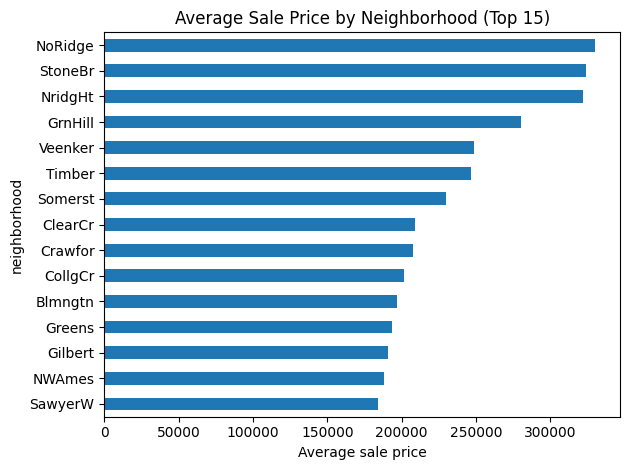

In [3]:
numeric_cols = [
    "saleprice",
    "bedroom_abvgr",
    "mo_sold",
    "yr_sold"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["saleprice"])
df = df[df["saleprice"] > 0].copy()

for col in ["neighborhood", "bldg_type"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown").astype(str).str.strip()

if "bedroom_abvgr" in df.columns:
    df["bedroom_abvgr"] = df["bedroom_abvgr"].fillna(
        df["bedroom_abvgr"].median()
    )
if {"mo_sold", "yr_sold"}.issubset(df.columns):
    df["sale_date"] = pd.to_datetime(
        {
            "year": df["yr_sold"],
            "month": df["mo_sold"],
            "day": 1
        },
        errors="coerce"
    )

if "neighborhood" in df.columns:
    df = df[df["neighborhood"] != "Unknown"]


if {"neighborhood", "saleprice"}.issubset(df.columns):
    neighborhood_summary = (
        df.groupby("neighborhood")["saleprice"]
        .agg(["count", "mean", "median", "min", "max"])
        .sort_values("mean", ascending=False)
    )

    print("\nSales summary by neighborhood:")
    print(neighborhood_summary)


    top_neighborhoods = neighborhood_summary.head(15)["mean"].sort_values()
    top_neighborhoods.plot(
        kind="barh",
        title="Average Sale Price by Neighborhood (Top 15)"
    )
    plt.xlabel("Average sale price")
    plt.tight_layout()
    plt.show()

In [4]:
if {"bldg_type", "saleprice"}.issubset(df.columns):
    property_summary = (
        df.groupby("bldg_type")["saleprice"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    print("\nSales summary by property type:")
    print(property_summary)


Sales summary by property type:
           count           mean    median
bldg_type                                
TwnhsE       233  192311.914163  180000.0
1Fam        2425  184812.041237  165000.0
Duplex       109  139808.935780  136905.0
Twnhs        101  135934.059406  130000.0
2fmCon        62  125581.709677  122250.0


In [5]:
df.to_csv("RealEstate_Wrangled.csv", index=False)

columns_to_encode = [
    col for col in ["neighborhood", "bldg_type"]
    if col in df.columns
]
encoded_df = pd.get_dummies(df, columns=columns_to_encode, dtype=int)
encoded_df.to_csv("RealEstate_Wrangled_Encoded.csv", index=False)

print("\nCleaned dataset saved as RealEstate_Wrangled.csv")
print("Encoded dataset saved as RealEstate_Wrangled_Encoded.csv")


Cleaned dataset saved as RealEstate_Wrangled.csv
Encoded dataset saved as RealEstate_Wrangled_Encoded.csv

Submitted by: Prajwal Vitkar
Roll No:4167
